# mctx's MuZero search in expex

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/davidesartor/expex/blob/main/examples/notebooks/mctx.ipynb)

> **Python 3.14+ is needed.** expex requires Python 3.14, and Colab's hosted runtimes ship
> Python 3.12 (the 2026.01 runtime has 3.12.12), so on a hosted runtime the setup cell stops
> with a message. To run this notebook in Colab, start Jupyter on Python 3.14 on your machine
> and use *Connect → Connect to a local runtime*
> ([how](https://github.com/davidesartor/expex/blob/main/examples/notebooks/README.md#running-in-colab)),
> or open it in Jupyter directly. If *Runtime → Change runtime type* offers a runtime with
> Python 3.14, that works too. The outputs below are from a run on a CPU.

A port of [mctx](https://github.com/google-deepmind/mctx)'s MuZero and Gumbel MuZero tree
search to expex: [`examples/mctx/search.py`](../mctx/search.py), 340 lines of code against 691
across 7 files. mctx searches a batch of trees at once (tree arrays with a batch axis, a
`lax.fori_loop` around `vmap`ped `lax.while_loop`s). The port writes the search for **one**
tree, with plain Python (`while node != ROOT:`, `visits[parent] += 1`), and a call on a batch
of roots maps over them.

This notebook searches a small random MDP, shows what expex reads from the annotations, checks
every tree against mctx's saved searches, and times it.

In [1]:
# Setup: install expex from GitHub (or use a local checkout) and fetch the examples.
EXPEX_REF = "main"  # the branch or tag of github.com/davidesartor/expex to install

import os, pathlib, subprocess, sys

if sys.version_info < (3, 14):
    raise RuntimeError(
        f"expex needs Python 3.14+, and this runtime has Python {sys.version.split()[0]}: "
        "connect to a local runtime with Python 3.14 (see the note at the top of the notebook)"
    )


def find_checkout() -> pathlib.Path | None:
    """A local checkout of expex: $EXPEX_REPO, or a folder above the working directory."""
    if os.environ.get("EXPEX_REPO"):
        return pathlib.Path(os.environ["EXPEX_REPO"]).resolve()
    for folder in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (folder / "src" / "expex").is_dir() and (folder / "examples").is_dir():
            return folder
    return None


def run(*cmd: str) -> None:
    subprocess.run(cmd, check=True)


REPO = find_checkout()
if REPO is None:  # Colab, or a notebook opened on its own: install from GitHub
    REPO = pathlib.Path("expex").resolve()
    run(sys.executable, "-m", "pip", "install", "-q", f"git+https://github.com/davidesartor/expex@{EXPEX_REF}")
    if not REPO.exists():  # the examples and the reference outputs of the originals
        run("git", "clone", "-q", "--depth", "1", "--branch", EXPEX_REF, "https://github.com/davidesartor/expex", str(REPO))
else:
    try:
        import expex  # noqa: F401
    except ImportError:
        run(sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO))
sys.path.insert(0, str(REPO / "examples" / "mctx"))
print("Python", sys.version.split()[0], "| examples from", REPO.name)

Python 3.14.6 | examples from vigilant-barnacle


In [2]:
import inspect
import time

import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np

import expex
import search  # examples/mctx/search.py
from search import ROOT, Tree, gumbel_muzero_policy, muzero_policy, random_mdp, recurrent_fn

print(inspect.getsource(search.search))
print(inspect.getsource(Tree.backward))

@expex.fn(examples={"params": [None]})
def search[S, A, E](
    params: Any,
    select_keys: Key[S],
    model_keys: Key[S],
    root: Root[A, E],
    model: Callable[..., tuple[Step[A], f32[E]]],
    select_root: Select,
    select_interior: Select,
    invalid: Bool[A],
    gumbel: f32[A],
    max_depth: int | None = None,
) -> Tree[S + 1, A, E]:
    """S simulations, each adding one node (mctx's `search`, for one tree)."""
    tree = new_tree(root, S + 1, invalid, gumbel)
    for sim in range(S):
        parent, action = tree.simulate(select_keys[sim], select_root, select_interior, max_depth)
        child = tree.children_index[parent, action]
        if child == UNVISITED:  # else max_depth was reached: evaluate the leaf again
            child = sim + 1
        tree = tree.expand(params, model_keys[sim], model, parent, action, child)
        tree = tree.backward(child)
    return tree

    def backward(self, leaf: i32) -> Tree[N, A, E]:
        """Back the leaf's value up to the 

## The annotated signatures

Every typed function and method in the module, as expex reads it:

In [3]:
def signature(f):
    owner = f.name.rpartition(".")[0]
    return f"{owner}.{f.signature}" if owner else f.signature


for report in expex.prove(search):
    print(signature(report.fn))

Tree.qvalues(self: Tree, node: i32[()]) -> f32[A]
Tree.summary(self: Tree) -> Summary[A]
Tree.simulate(self: Tree, key: Key, select_root: Select, select_interior: Select, max_depth: Union) -> tuple[i32[()], i32[()]]
Tree.expand(self: Tree, params, key: Key, model: Callable, parent: i32[()], action: i32[()], child: i32[()]) -> Tree[N, A, E]
Tree.fill(self: Tree, node: i32[()], prior_logits: f32[A], value: f32[()], embedding: f32[E]) -> Tree[N, A, E]
Tree.backward(self: Tree, leaf: i32[()]) -> Tree[N, A, E]
new_tree[A, E](root: Root[A, E], nodes: int, invalid: Bool[A], gumbel: f32[A]) -> Tree[nodes, A, E]
search[S, A, E](params, select_keys: Key[S], model_keys: Key[S], root: Root[A, E], model: Callable, select_root: Select, select_interior: Select, invalid: Bool[A], gumbel: f32[A], max_depth: Union) -> Tree[S + 1, A, E]
search_keys(key: Key, simulations: int) -> tuple[Key[simulations], Key[simulations]]
qtransform_by_parent_and_siblings[N, A, E](tree: Tree[N, A, E], node: i32[()], epsilo

`expex.debug.shapes` shows the shape of every line, for all sizes at once:

In [4]:
print(expex.debug.shapes(search.muzero_action_selection))

muzero_action_selection[N, A, E](key: Key, tree: Tree[N, A, E], node: i32[()], depth: i32[()], pb_c_init: float, pb_c_base: float, qtransform: Callable) -> i32[()]   [symbolic A, E, N]
  278 | @expex.fn
  279 | def muzero_action_selection[N, A, E](
  280 |     key: Key,
  281 |     tree: Tree[N, A, E],
  282 |     node: i32,
  283 |     depth: i32,
  284 |     *,
  285 |     pb_c_init: float = 1.25,
  286 |     pb_c_base: float = 19652.0,
  287 |     qtransform: Callable[..., f32[A]] = qtransform_by_parent_and_siblings,
  288 | ) -> i32:
  289 |     """The PUCT rule (MuZero, Appendix B), with a tiny noise to break ties."""
  290 |     visits, node_visits = tree.children_visits[node], tree.node_visits[node]   # visits: i32[A], node_visits: i32[()]
  291 |     pb_c = pb_c_init + jnp.log((node_visits + pb_c_base + 1.0) / pb_c_base)   # pb_c: f32[()]
  292 |     prior = jax.nn.softmax(tree.children_prior_logits[node])               # prior: f32[A]
  293 |     policy_score = jnp.sqrt(node_v

## Run it

A random deterministic MDP with 12 states and 4 actions (its tables stand in for the policy and
value networks), and a batch of 8 roots, searched with 32 simulations each:

In [5]:
mdp = random_mdp(jr.key(0), 12, 4)
roots = mdp.root(jnp.arange(8))  # 8 roots: mapped over the states
print("roots:", expex.show(roots))

for policy in (muzero_policy, gumbel_muzero_policy):
    out = jax.jit(policy, static_argnums=(3, 4))(mdp, jr.key(1), roots, recurrent_fn, 32)
    print(f"{policy.__name__}: actions {out.action}, root visits of tree 0 {out.search_tree.children_visits[0, ROOT]}")
print("trees:", expex.show(out.search_tree))

roots: Root(prior_logits=f32[8, 4], value=f32[8], embedding=f32[8, 12])


muzero_policy: actions [1 1 3 3 1 2 3 3], root visits of tree 0 [ 2 30  0  0]


gumbel_muzero_policy: actions [1 0 3 2 1 2 3 2], root visits of tree 0 [ 4 12 12  4]
trees: Tree(node_visits=i32[8, 33], raw_values=f32[8, 33], node_values=f32[8, 33], parents=i32[8, 33], action_from_parent=i32[8, 33], children_index=i32[8, 33, 4], children_prior_logits=f32[8, 33, 4], children_visits=i32[8, 33, 4], children_rewards=f32[8, 33, 4], children_discounts=f32[8, 33, 4], children_values=f32[8, 33, 4], embeddings=f32[8, 33, 12], root_invalid_actions=Bool[8, 4], root_gumbel=f32[8, 4])


The loops and branches were staged as written: `while` as `lax.while_loop`, `for` as
`lax.scan`, `if` as `lax.cond`:

In [6]:
print("Tree.simulate:", Tree.simulate.flow)
print("Tree.backward:", Tree.backward.flow)
print("search:       ", search.search.flow)

Tree.simulate: {117: 'while -> lax.while_loop'}
Tree.backward: {161: 'while -> lax.while_loop'}
search:        {211: 'for -> lax.scan (carries tree)', 214: 'if -> lax.cond'}


## What the annotations give

**Proofs** for every size, without data:

In [7]:
expex.prove(search)

ok    search.Tree.qvalues
ok    search.Tree.summary
ok    search.Tree.simulate
ok    search.Tree.expand
ok    search.Tree.fill
ok    search.Tree.backward
ok    search.new_tree
ok    search.search
ok    search.search_keys
ok    search.qtransform_by_parent_and_siblings
ok    search.qtransform_completed_by_mix_value
ok    search.mixed_value
ok    search.muzero_action_selection
ok    search.gumbel_muzero_root_action_selection
ok    search.gumbel_muzero_interior_action_selection
ok    search.masked_argmax
ok    search.score_considered
ok    search.mask_invalid
ok    search.logits_of
ok    search.with_temperature
ok    search.muzero_policy
ok    search.gumbel_muzero_policy
ok    search.gumbel_decision
ok    search.MDP.root
ok    search.MDP.step
ok    search.random_mdp

26 functions: 26 proved

**Cost** of a selection step and of one search, as formulas in the sizes (a `while` loop counts
one iteration, and says so):

In [8]:
print(expex.cost(search.muzero_action_selection))
print(expex.cost(Tree.backward))

muzero_action_selection   (sizes: A)
  flops        29·A + 38
  largest      i32[A] (A elements)
Tree.backward   (sizes: N, A, E)
  flops        2·N·A + 2·N + 74
  parameters   6·N·A + N·E + 5·N + 2·A
  largest      f32[N,A] (N·A elements)
  note: while loop at examples/mctx/search.py:168 (Tree.backward): trip count unknown, one iteration counted


**A summary** of one search tree's arrays (tree 0 of the batch):

In [9]:
expex.summary(jax.tree.map(lambda x: x[0], out.search_tree))

Tree   (N=33, A=4, E=12)
module                 class        params  formula                    bytes  flops  flops formula
──────────────────────────────────────────────────────────────────────────────────────────────────
node_visits            i32[N]           33  N                          132 B
raw_values             f32[N]           33  N                          132 B
node_values            f32[N]           33  N                          132 B
parents                i32[N]           33  N                          132 B
action_from_parent     i32[N]           33  N                          132 B
children_index         i32[N, A]       132  N·A                        528 B
children_prior_logits  f32[N, A]       132  N·A                        528 B
children_visits        i32[N, A]       132  N·A                        528 B
children_rewards       f32[N, A]       132  N·A                        528 B
children_discounts     f32[N, A]       132  N·A                        528 B
childre

**A diagram** of the search for one tree, drawn from the code (interactive when you run the
notebook: click a call to open it). The loop over simulations is a dashed container `loop × S`.

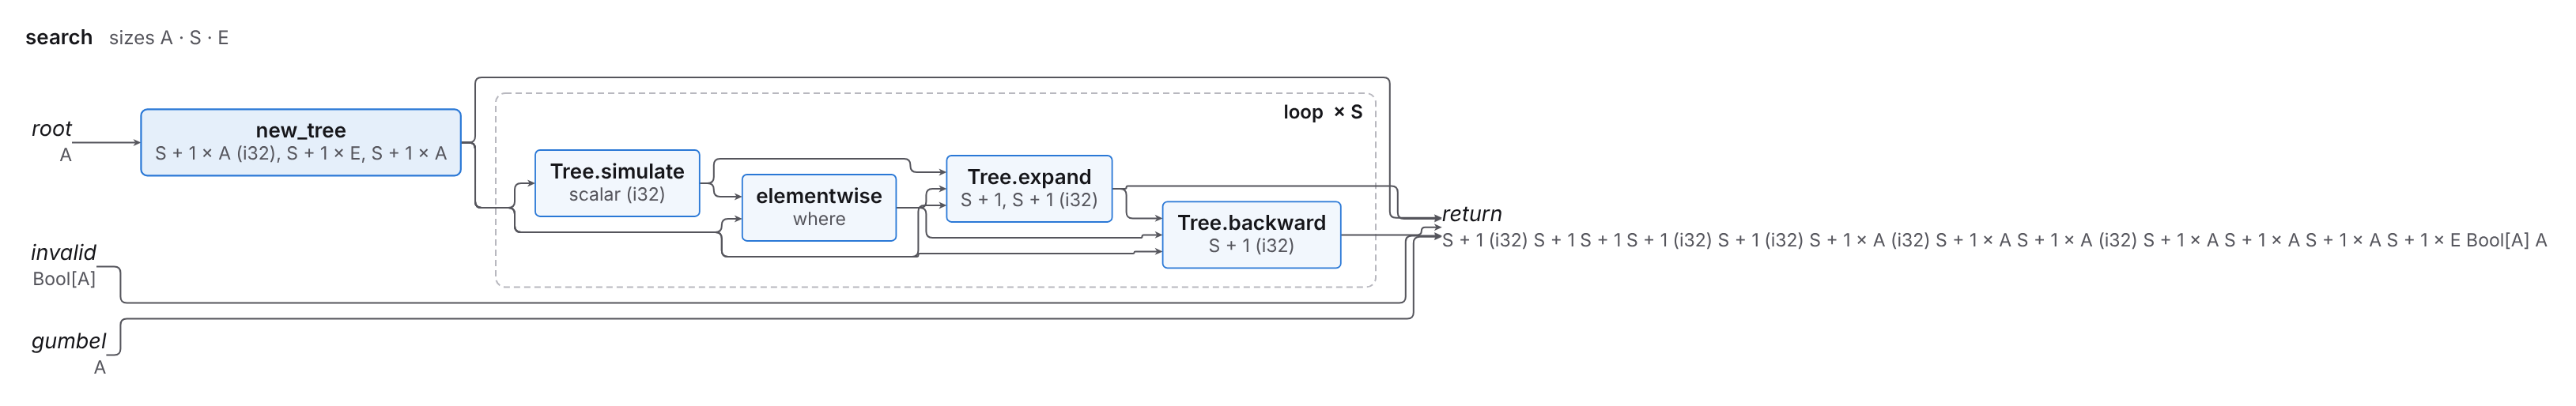

In [10]:
expex.diagram(search.search)

`expex.inspect` and `expex.debug.watch` are for models with a `__call__` and a loss; a search
has neither, so they are not used here.

## A shape error

The invalid-action mask must have one entry per action of the roots. A mask for 5 actions,
where the roots have 4, is refused with the size it disagrees with:

In [11]:
try:
    muzero_policy(mdp, jr.key(1), roots, recurrent_fn, 8, jnp.zeros((8, 5), bool))
except expex.ShapeError as e:
    error = e
error

ShapeError: muzero_policy(): argument `invalid_actions` does not match its annotation.

    declared  invalid_actions: Bool[B, A]
    received                   Bool[8, 5]

    A is 4 (from `root.prior_logits: f32[8, 4]`), but axis 1 of `invalid_actions` is 5.

    muzero_policy[B, A, E](params, key: Key, root: Batch[Root[A, E], B], recurrent_fn: Callable, num_simulations: int, invalid_actions: Bool[B, A] | None, max_depth: Union, qtransform: Callable, dirichlet_fraction: float, dirichlet_alpha: float, pb_c_init: float, pb_c_base: float, temperature: float) -> Batch[Policy[num_simulations + 1, A, E], B]
    defined at examples/mctx/search.py:395
  see https://github.com/davidesartor/expex/blob/main/docs/errors.md#ex101


## Against the original

`tests/data/mctx_reference.npz` holds searches by the unmodified mctx on a fixed random MDP: a
batch of 8 trees, with MuZero and Gumbel MuZero, with and without an invalid-action mask and a
`max_depth`. For each case, the chosen actions, the action weights and every array of the final
trees. `compare.py` runs the port on the same problem and keys; the largest difference per case
(0 is bit-identical):

In [12]:
import compare  # examples/mctx/compare.py

reference = dict(np.load(REPO / "tests" / "data" / "mctx_reference.npz"))
for case, diffs in compare.compare(reference).items():
    print(f"{case:13} largest difference {max(diffs.values()):.3g} over {len(diffs)} outputs")

muzero        largest difference 0 over 16 outputs
muzero_depth  largest difference 0 over 16 outputs
gumbel        largest difference 0 over 17 outputs
gumbel_depth  largest difference 0 over 17 outputs


## Speed

Searches per second, a batch of 64 roots with 32 simulations, jitted. Timings depend on the
machine. With mctx checked out, `python examples/mctx/compare.py` times both; the repository's
[benchmarks/](../../benchmarks/) report the same speed on CPU (best of 25 rounds, median in
brackets): MuZero 1.02x (0.98x), Gumbel MuZero 1.08x (1.11x).

In [13]:
roots64 = mdp.root(jnp.arange(64) % 12)
for policy in (muzero_policy, gumbel_muzero_policy):
    run = jax.jit(policy, static_argnums=(3, 4))
    jax.block_until_ready(run(mdp, jr.key(0), roots64, recurrent_fn, 32))  # compile
    times = []
    for i in range(10):
        start = time.perf_counter()
        jax.block_until_ready(run(mdp, jr.key(i), roots64, recurrent_fn, 32))
        times.append(time.perf_counter() - start)
    print(f"{policy.__name__:20} {np.median(times) * 1e3:6.2f} ms per batch of 64 searches")

muzero_policy          4.39 ms per batch of 64 searches


gumbel_muzero_policy   1.41 ms per batch of 64 searches
